# Распознаём свои рукописные цифры

Загружаем UMAP и kNN, обученные в `dimensionality_reduction.ipynb` (раздел 2), и проверяем их на цифрах, которые я нарисовал сам. Картинки лежат в `data/handwritten_figures/0.jpg ... 9.jpg`.

Чтобы картинка была похожа на MNIST: переводим в чёрно-белую, уменьшаем до 28x28 и инвертируем (в MNIST цифра белая на чёрном фоне).

In [1]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import cv2

umap_mnist = joblib.load('models/umap_mnist.joblib')
knn = joblib.load('models/knn_mnist.joblib')

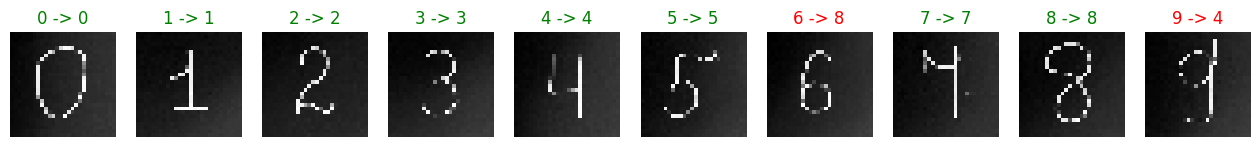

угадано 8 из 10


In [2]:
def prepare(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (28, 28))
    img = 255 - img
    return img / 255


figures = np.array([prepare(f'data/handwritten_figures/{i}.jpg') for i in range(10)])
figures_umap = umap_mnist.transform(figures.reshape(10, -1))
pred = knn.predict(figures_umap)

fig, axes = plt.subplots(1, 10, figsize=(16, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(figures[i], cmap='gray')
    ax.set_title(f'{i} -> {pred[i]}', color='green' if pred[i] == i else 'red')
    ax.axis('off')
plt.savefig('images/my_digits.png', dpi=80, bbox_inches='tight')
plt.show()

print('угадано', (pred == np.arange(10)).sum(), 'из 10')

In [3]:
# сжатые векторы моих цифр
figures_umap

array([[14.261079  ,  1.9395858 ],
       [-2.5166183 , 13.114749  ],
       [ 1.6687955 , 11.013603  ],
       [ 5.8948283 ,  4.28436   ],
       [ 0.30588543, -3.4721766 ],
       [ 2.5757954 ,  4.1558676 ],
       [ 2.9466813 ,  1.5632249 ],
       [-3.7464287 , -1.7103758 ],
       [ 2.0731628 ,  3.0720985 ],
       [ 0.38421863, -3.289032  ]], dtype=float32)

Угадано 8 из 10: 6 модель приняла за 8, а 9 за 4. Мои цифры нарисованы тонкой пунктирной линией на сером фоне, а в MNIST линии толстые и фон чисто чёрный, поэтому картинки заметно отличаются от обучающих. У 9 верхняя петля почти замкнута, но есть черта похожая на часть 4. Можно улучшить, если сделать линии толще и обнулить фон перед сжатием.